1. What is GAN?
GAN stands for Generative Adversarial Network.
It is a Deep Learning architecture used to generate new data that looks similar to the training data.
For example:
- Generate human faces.
- Generate handwritten digits.
- Generate cartoon images.
- Generate artificial product images.
- Generate realistic images.

A GAN contains two neural networks:
1. Generator
2. Discriminator

A. Generator
The Generator creates new images using random noise.

For example:

Input: Random numbers

Output: A generated handwritten digit image.
B. Discriminator
The Discriminator checks whether an image is:
- Real: An image from the original dataset.
- Fake: An image generated by the Generator.

How do they work together?
Think of this as a competition:
Generator	                                      Discriminator
Tries to generate realistic images	            Tries to identify fake images
Learns from feedback	                          Learns from real and fake images
Wants to fool Discriminator	                    Wants to detect generated images

Important concept: Both networks improve through competition. Eventually, the Generator
learns to create images that look similar to the original dataset.


In [1]:
#Our objective:
#Build a GAN model that learns from handwritten digit images and generates new handwritten digits.
!pip install tensorflow

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers
# Explanation:
# - tensorflow: Deep Learning framework.
# - numpy: Handles numerical operations.
# - matplotlib: Displays images.
# - layers: Provides Dense, Conv2D, Flatten, etc.

In [3]:
# Step 3: Load the MNIST dataset
# MNIST contains 70,000 handwritten digit images.
# - 60,000 training images.
# - 10,000 testing images.
# - Each image has dimensions 28 × 28.
# - Each image contains a digit between 0 and 9.

# Load MNIST dataset

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
# Check dataset shape
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


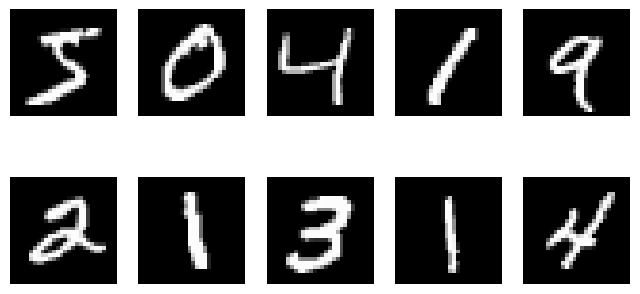

In [4]:
#Display Some original images
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")

plt.show()

In [5]:
# Step 4: Preprocess the images
# Our original pixel values range from 0 to 255.
# We need to normalize these values between -1 and +1.
# Why?
# Because our Generator will use the tanh activation function,
# which produces values between -1 and +1.
# Convert images to float32

x_train = x_train.astype("float32")
# Normalize pixel values from 0-255 to -1 to +1
x_train = (x_train - 127.5) / 127.5
# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
print(x_train.shape)
# Why do we add the channel dimension?
# Because CNN models expect image data in this format:
# (height, width, channels)
# Our images are grayscale, so channels = 1.

(60000, 28, 28, 1)


In [6]:
#Step 5: Prepare the training dataset
BUFFER_SIZE = 60000
BATCH_SIZE = 256
train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE)
train_dataset = train_dataset.batch(BATCH_SIZE)
# Explanation:
# - shuffle(): Randomly changes image order.
# - batch(): Divides images into groups of 256.
# - from_tensor_slices(): Converts our training images
# into a TensorFlow dataset.

In [7]:
# Step 6: Create the Generator
# Now we will build our first neural network.
# The Generator takes 100 random numbers and generates a 28 × 28 image.
def build_generator():
    model = tf.keras.Sequential()
    # Input: 100 random numbers
    model.add(layers.Input(shape=(100,)))
    # Convert noise into 7*7*128 values
    model.add(layers.Dense(7 * 7 * 128))

    # Normalize values
    model.add(layers.BatchNormalization())

    # Apply activation
    model.add(layers.LeakyReLU())

    # Reshape into feature maps
    model.add(layers.Reshape((7, 7, 128)))

    # Increase image size from 7x7 to 14x14
    model.add(
        layers.Conv2DTranspose(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.BatchNormalization())

    model.add(layers.LeakyReLU())

    # Increase image size from 14x14 to 28x28
    model.add(
        layers.Conv2DTranspose(
            1,
            kernel_size=5,
            strides=2,
            padding="same",
            activation="tanh"
        )
    )

    return model

In [8]:
# Let's understand the important layers.
# Layer	                          Purpose
# Dense	                          Converts random noise into feature values
# Batch                           Normalization	Stabilizes training
# Leaky                           ReLU	Adds non-linearity
# Reshape                       	Converts features into 7 × 7 feature maps
# Conv2D                          Transpose	Upsamples feature maps
# Tanh	                          Generates pixel values between -1 and +1

In [9]:
#Create the Generator:
generator = build_generator()
generator.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,864 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865,281 (3.30 MB)

 Trainable params: 852,609 (3.25 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [10]:
# Generate 1 random noise vector
noise = tf.random.normal([1, 100])
# Generate an image
generated_image = generator(noise, training=False)
print(generated_image.shape)

(1, 28, 28, 1)


In [11]:
# Step 7: Create the Discriminator
# Now let's create the second neural network.
# The Discriminator receives an image and predicts whether it is real or fake.
def build_discriminator():

    model = tf.keras.Sequential()

    # Input image: 28x28 grayscale
    model.add(layers.Input(shape=(28, 28, 1)))

    # First convolution layer
    model.add(
        layers.Conv2D(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Second convolution layer
    model.add(
        layers.Conv2D(
            128,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Convert feature maps into a vector
    model.add(layers.Flatten())

    # Final output
    model.add(layers.Dense(1))

    return model

In [12]:
discriminator = build_discriminator()
discriminator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Important: The final Dense layer has one output and no sigmoid activation. It produces a raw score called a logit.
# - Higher score: More likely to be real.
# - Lower score: More likely to be fake.
# We will use BinaryCrossentropy(from_logits=True) to calculate the loss.
# Step 8: Define loss functions
# Now comes the most important part of GAN training.
# We need two loss functions.
# 1. Generator Loss
# 2. Discriminator Loss

In [14]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)

In [15]:
# Discriminator Loss:
# The Discriminator should identify real images as 1 and fake images as 0.
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    total_loss = real_loss + fake_loss

    return total_loss

In [16]:
# Generator Loss:
# The Generator wants the Discriminator to classify its fake images as real.
# Therefore, the Generator tries to produce outputs with target labels of 1.

In [17]:
def generator_loss(fake_output):

    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

In [18]:
# Understand this carefully:
# Network	                      Target label
# Discriminator + real image	    1
# Discriminator + fake image	    0
# Generator's fake image	        1

# The Generator uses label 1 because it wants to fool the Discriminator.

In [19]:
# Step 9: Define optimizers
# We use Adam optimizers to update the weights of both networks.

In [20]:
# Step 9: Define optimizers
# We use Adam optimizers to update the weights of both networks.
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

# Why two optimizers?
# Because the Generator and Discriminator have different trainable weights
# and are trained separately.

In [21]:
# Step 10: Create the GAN training function
# Most important step
# This is where both neural networks learn together.

# The training process:
# 1. Take real images from MNIST.
# 2. Generate random noise.
# 3. Pass random noise into the Generator.
# 4. Get fake images.
# 5. Pass real and fake images into the Discriminator.
# 6. Calculate Discriminator loss.
# 7. Update Discriminator weights.
# 8. Generate fake images again.
# 9. Calculate Generator loss.
# 10. Update Generator weights.

In [22]:
# Define noise dimension

noise_dim = 100


@tf.function
def train_step(real_images):

    # Number of images in current batch
    batch_size = tf.shape(real_images)[0]

    # Generate random noise
    noise = tf.random.normal([batch_size, noise_dim])

    # --------------------------------
    # Train Discriminator
    # --------------------------------

    with tf.GradientTape() as disc_tape:

        # Generate fake images
        generated_images = generator(noise, training=True)

        # Discriminator predictions on real images
        real_output = discriminator(
            real_images,
            training=True
        )

        # Discriminator predictions on fake images
        fake_output = discriminator(
            tf.stop_gradient(generated_images),
            training=True
        )

        # Calculate discriminator loss
        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients
    disc_gradients = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update discriminator weights
    discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            discriminator.trainable_variables
        )
    )

    # --------------------------------
    # Train Generator
    # --------------------------------

    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as gen_tape:

        # Generate new fake images
        generated_images = generator(
            noise,
            training=True
        )

        # Ask discriminator to classify fake images
        fake_output = discriminator(
            generated_images,
            training=True
        )

        # Generator wants fake images to be classified as real
        gen_loss = generator_loss(fake_output)

    # Calculate generator gradients
    gen_gradients = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    # Update generator weights
    generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            generator.trainable_variables
        )
    )

    return gen_loss, disc_loss

In [23]:
# Understand two important concepts:
# tf.GradientTape() tracks operations so TensorFlow can calculate gradients.
# tf.stop_gradient() prevents the Discriminator training step from updating
# the Generator's weights.
# During the Generator training step,
# gradients are allowed to flow through the Discriminator into the Generator.
# However, we apply those gradients only to the Generator's weights.
# This separation is essential.

In [24]:
# Step 11: Train the GAN model
# Now we will train both networks.
EPOCHS = 30

for epoch in range(EPOCHS):

    gen_loss_total = 0
    disc_loss_total = 0
    batches = 0

    for image_batch in train_dataset:

        gen_loss, disc_loss = train_step(image_batch)

        gen_loss_total += gen_loss
        disc_loss_total += disc_loss

        batches += 1

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Generator Loss: {gen_loss_total / batches:.4f} | "
        f"Discriminator Loss: {disc_loss_total / batches:.4f}"
    )

Epoch 1/30 | Generator Loss: 0.7863 | Discriminator Loss: 1.1941
Epoch 2/30 | Generator Loss: 0.7939 | Discriminator Loss: 1.3171
Epoch 3/30 | Generator Loss: 0.8311 | Discriminator Loss: 1.2856
Epoch 4/30 | Generator Loss: 0.8768 | Discriminator Loss: 1.2305
Epoch 5/30 | Generator Loss: 0.9332 | Discriminator Loss: 1.1962
Epoch 6/30 | Generator Loss: 0.9429 | Discriminator Loss: 1.2143
Epoch 7/30 | Generator Loss: 0.9246 | Discriminator Loss: 1.2534
Epoch 8/30 | Generator Loss: 0.8773 | Discriminator Loss: 1.2603
Epoch 9/30 | Generator Loss: 0.8664 | Discriminator Loss: 1.2671
Epoch 10/30 | Generator Loss: 0.8695 | Discriminator Loss: 1.2667
Epoch 11/30 | Generator Loss: 0.8673 | Discriminator Loss: 1.2709
Epoch 12/30 | Generator Loss: 0.8681 | Discriminator Loss: 1.2677
Epoch 13/30 | Generator Loss: 0.8629 | Discriminator Loss: 1.2720
Epoch 14/30 | Generator Loss: 0.8622 | Discriminator Loss: 1.2698
Epoch 15/30 | Generator Loss: 0.8638 | Discriminator Loss: 1.2700
Epoch 16/30 | Gener

In [25]:
# Important teaching point: GAN losses do not necessarily decrease smoothly.
# Both networks compete with each other, so fluctuations are normal.

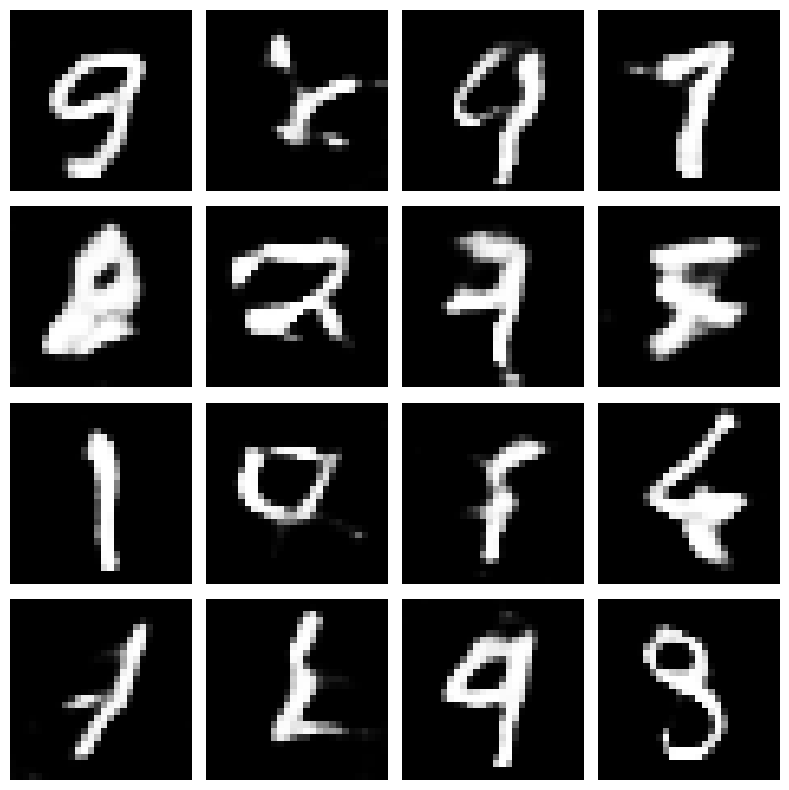

In [26]:
# Step 12: Generate new images
# Final output
# Now our Generator has learned from the MNIST dataset.
# Let's generate 16 new images.
# Generate 16 random noise vectors

noise = tf.random.normal([16, noise_dim])

# Generate images

predictions = generator(noise, training=False)

# Display generated images

plt.figure(figsize=(8, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    # Convert pixel values from -1 to +1 into 0 to 1
    image = (predictions[i, :, :, 0] + 1) / 2

    plt.imshow(image, cmap="gray")

    plt.axis("off")

plt.tight_layout()

plt.show()